In [ ]:
print("Hello Buddy! My Python Data Analyst Journey Starts Today!")

Hello Buddy! My Python Data Analyst Journey Starts Today!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving retail_sales_project (1) (1).csv to retail_sales_project (1) (1).csv


In [ ]:
import pandas as pd

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

df.head()

,order_id,order_date,region,category,product,quantity,unit_price,unit_cost
0,ORD0001,13-01-2025,South,Electronics,Mouse,5,18,8.0
1,ORD0002,13-03-2025,North,Furniture,Office Chair,2,140,90.0
2,ORD0003,05-08-2025,North,Electronics,Monitor,1,210,160.0
3,ORD0004,22-04-2025,North,Electronics,Mouse,4,18,8.0
4,ORD0005,12-04-2025,South,Accessories,Backpack,7,45,22.0


In [ ]:
print('Dataset type')
print(df.shape)

print("\nDataset Information:")
print(df.info())

print('\nstatistical summary')
print(df.describe())

Dataset type
(120, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   order_id    120 non-null    object 
 1   order_date  120 non-null    object 
 2   region      120 non-null    object 
 3   category    120 non-null    object 
 4   product     120 non-null    object 
 5   quantity    120 non-null    int64  
 6   unit_price  120 non-null    int64  
 7   unit_cost   120 non-null    float64
dtypes: float64(1), int64(2), object(5)
memory usage: 7.6+ KB
None

statistical summary
         quantity  unit_price   unit_cost
count  120.000000  120.000000  120.000000
mean     4.375000  118.800000   84.154167
std      2.134402  162.452041  130.258208
min      1.000000    4.000000    1.500000
25%      2.000000   18.000000    8.000000
50%      5.000000   45.000000   22.000000
75%      6.000000  157.500000  105.000000
max      8.000000 

In [ ]:
# check missing values
print('missing values:')
print(df.isnull().sum())
#check duplicate values
print('\nduplicate values')
print(df.duplicated().sum())
# Check column names
print('\ncolumn names')
print(df.columns)

missing values:
order_id      0
order_date    0
region        0
category      0
product       0
quantity      0
unit_price    0
unit_cost     0
dtype: int64

duplicate values
0

column names
Index(['order_id', 'order_date', 'region', 'category', 'product', 'quantity',
       'unit_price', 'unit_cost'],
      dtype='object')


In [ ]:
df['order_date'] = pd.to_datetime(df['order_date'])

print(df.dtypes)

order_id              object
order_date    datetime64[ns]
region                object
category              object
product               object
quantity               int64
unit_price             int64
unit_cost            float64
dtype: object


In [ ]:
# Calculate Revenue
df['Revenue'] =df['unit_price']*df['quantity']
# Calculate Profit
df['Profit']=(df['unit_price']-df['unit_cost'])*df['quantity']
df.head()


,order_id,order_date,region,category,product,quantity,unit_price,unit_cost,Revenue,Profit
0,ORD0001,2025-01-13,South,Electronics,Mouse,5,18,8.0,90,50.0
1,ORD0002,2025-03-13,North,Furniture,Office Chair,2,140,90.0,280,100.0
2,ORD0003,2025-08-05,North,Electronics,Monitor,1,210,160.0,210,50.0
3,ORD0004,2025-04-22,North,Electronics,Mouse,4,18,8.0,72,40.0
4,ORD0005,2025-04-12,South,Accessories,Backpack,7,45,22.0,315,161.0


In [ ]:
#Question 1: What is the total revenue generated from all sales?
df['Revenue'].sum()

np.int64(56275)

In [ ]:
# df['profit'].sum()
df['Profit'].sum()

np.float64(16861.5)

In [ ]:
#Question 3: Find the highest revenue-generating product
df.groupby('product')['Revenue'].sum().sort_values(ascending=False).head(1)

,Revenue
product,
Laptop,19500


In [ ]:
#Question 4: Find the highest profit-generating product
df.groupby('product')['Profit'].sum().sort_values(ascending=False).head(1)

,Profit
product,
Office Chair,4200.0


In [ ]:
#Question 5: Find total revenue by category
df.groupby('category')['Revenue'].sum()

,Revenue
category,
Accessories,3285
Electronics,31930
Furniture,20560
Stationery,500


In [ ]:
#Question 6: Find the highest revenue-generating region
df.groupby('region')['Revenue'].sum().sort_values(ascending=False)

,Revenue
region,
South,24806
East,13270
West,12261
North,5938


In [ ]:
#Question 7: Find total quantity sold by each category
df.groupby('category')['quantity'].sum()

,quantity
category,
Accessories,99
Electronics,209
Furniture,124
Stationery,93


In [ ]:
#Question 8: Find monthly revenue
df['month']=df['order_date'].dt.month
df.groupby('month')['Revenue'].sum().sort_values(ascending=False)

,Revenue
month,
4,7977
1,7622
3,6947
2,6714
8,5711
7,5224
12,4231
10,4071
11,2342


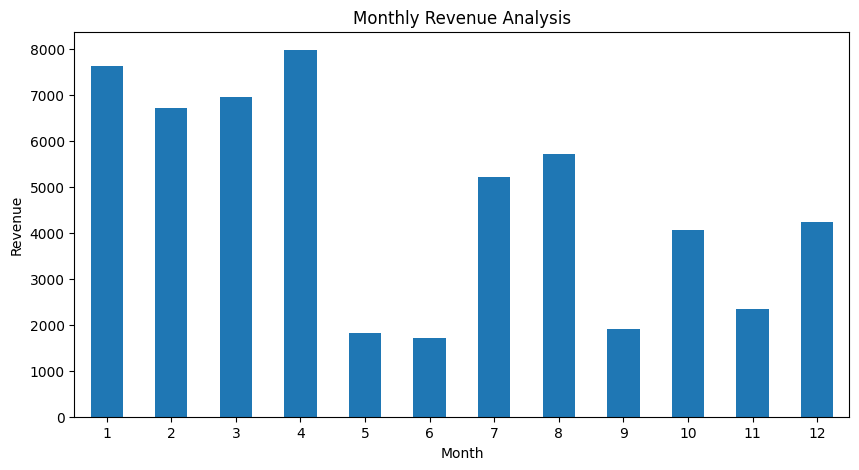

In [ ]:
# step 9:create a monthly revenue bar chart using Matplotlib.
monthly_revenue = df.groupby('month')['Revenue'].sum()

monthly_revenue.plot(
    kind='bar',
    figsize=(10,5),
    title='Monthly Revenue Analysis'
)

plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=0)
plt.show()

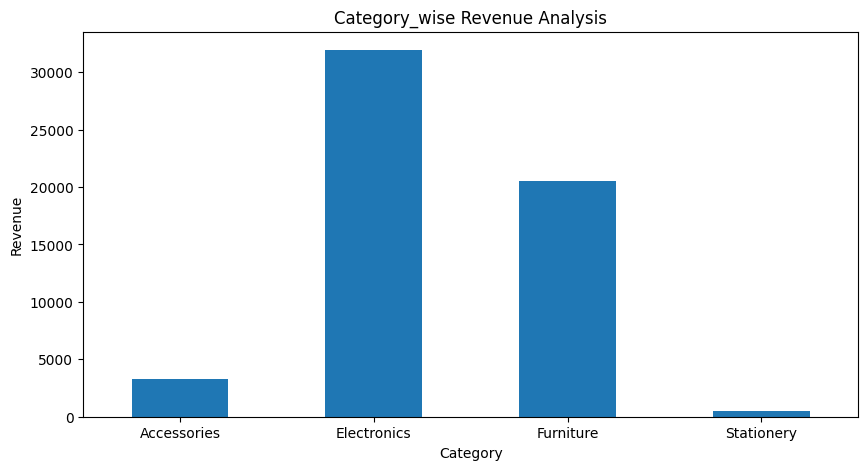

In [ ]:
#Step 10: Category-wise Revenue Chart
category_Revenue = df.groupby('category')['Revenue'].sum()

category_Revenue.plot(
    kind='bar',
    figsize=(10,5),
    title='Category_wise Revenue Analysis'
)
plt.xlabel('Category')
plt.ylabel('Revenue')
plt.xticks(rotation=0)
plt.show()

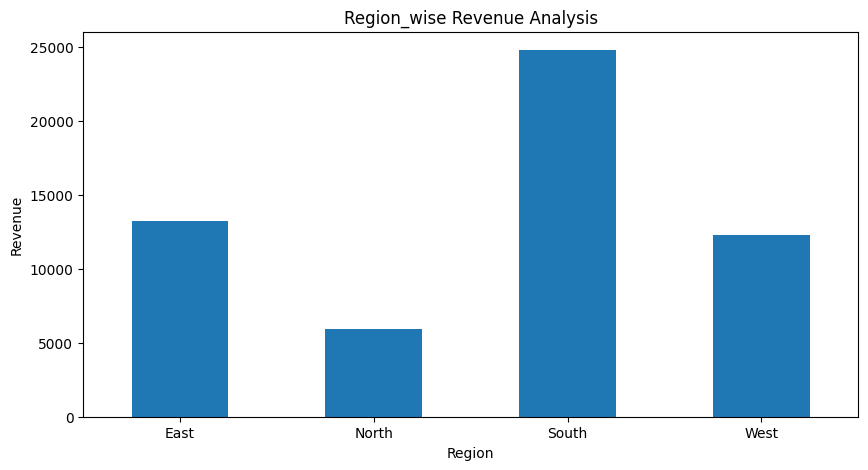

In [ ]:
#Step 11: Region-wise Revenue Chart

Region_Revenue = df.groupby('region')['Revenue'].sum()

Region_Revenue.plot(
    kind='bar',
    figsize=(10,5),
    title='Region_wise Revenue Analysis'
)
plt.xlabel('Region')
plt.ylabel('Revenue')
plt.xticks(rotation=0)
plt.show()


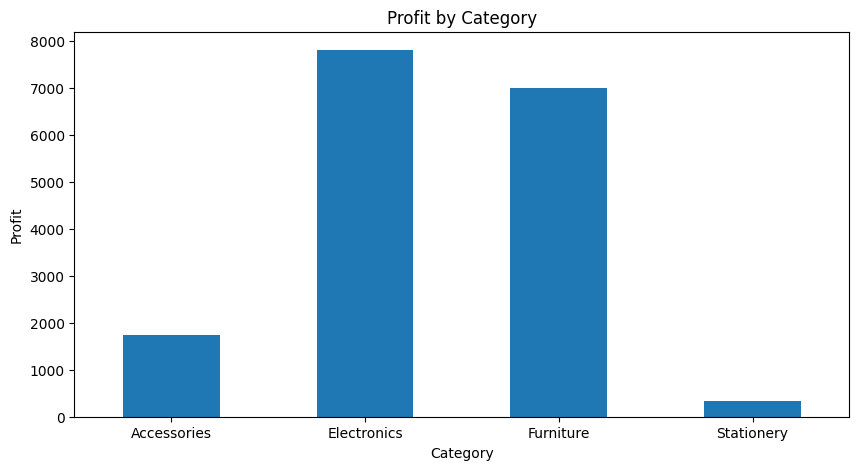

In [ ]:
#Step 12: Profit by Category
Profit_Category=df.groupby('category')['Profit'].sum()

Profit_Category.plot(
    kind='bar',
    figsize=(10,5),
    title='Profit by Category'
)
plt.xlabel('Category')
plt.ylabel('Profit')
plt.xticks(rotation=0)
plt.show()


In [ ]:
#Step 13: Find the most profitable region

profit_region=df.groupby('region')['Profit'].sum()
profit_region

,Profit
region,
East,4365.5
North,2206.5
South,6506.5
West,3783.0


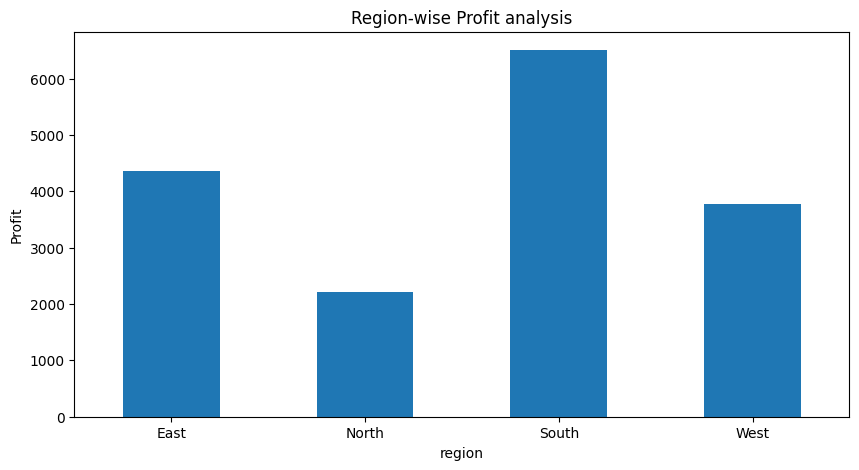

In [ ]:
#Step 14: Create a Region-wise Profit Chart
profit_region.plot(
    kind='bar',
    figsize=(10,5),
    title='Region-wise Profit analysis'
)
plt.xlabel('region')
plt.ylabel('Profit')
plt.xticks(rotation=0)
plt.show()


In [ ]:
#Step 15: Find the top 5 products by revenue
df.groupby('product')['Revenue'].sum().sort_values(ascending=False).head(5)

,Revenue
product,
Laptop,19500
Office Chair,11760
Monitor,9030
Desk,8800
Backpack,2700


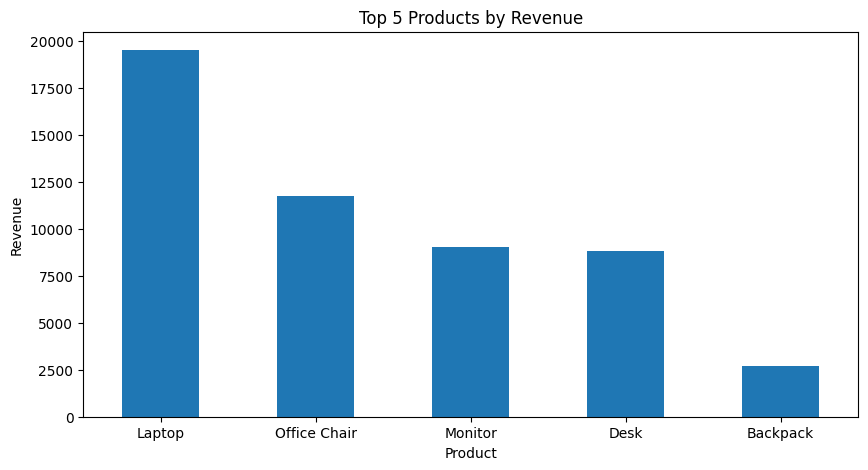

In [ ]:
#Step 16: Create a chart of the top 5 products
top_5_products = df.groupby('product')['Revenue'].sum().sort_values(ascending=False).head(5)

top_5_products.plot(
    kind='bar',
    figsize=(10,5),
    title='Top 5 Products by Revenue'
)
plt.xlabel('Product')
plt.ylabel('Revenue')
plt.xticks(rotation=0)
plt.show()


In [ ]:
#Step 17: Calculate the average order revenue
df['Revenue'].mean()

np.float64(468.9583333333333)

In [ ]:
#Step 18: Find the average profit per transaction
df['Profit'].mean()

np.float64(140.5125)

In [ ]:
#Step 19: Find the total quantity sold for each product
df.groupby('product')['quantity'].sum().sort_values(ascending=False)

,quantity
product,
Office Chair,84
Mouse,80
Pen Pack,64
Backpack,60
Keyboard,56
Monitor,43
Desk,40
Water Bottle,39
Laptop,30


In [ ]:
#Step 20: Find the total quantity sold by each category
df.groupby('category')['quantity'].sum().sort_values(ascending=False)

,quantity
category,
Electronics,209
Furniture,124
Accessories,99
Stationery,93


In [ ]:
#Step 21: Find the number of orders in each category
df.groupby('category')['order_id'].count().sort_values(ascending=False)

,order_id
category,
Electronics,47
Furniture,30
Accessories,24
Stationery,19


In [ ]:
#Step 22: Calculate the average revenue for each category
df.groupby('category')['Revenue'].mean().sort_values(ascending=False)

,Revenue
category,
Furniture,685.333333
Electronics,679.361702
Accessories,136.875000
Stationery,26.315789


In [ ]:
#Step 23: Find the average profit for each category
df.groupby('category')['Profit'].mean().sort_values(ascending=False)

,Profit
category,
Furniture,233.333333
Electronics,166.000000
Accessories,72.125000
Stationery,17.289474


In [ ]:
#Step 24: Find the highest revenue order
df.loc[df['Revenue'].idxmax()]

,66
order_id,ORD0067
order_date,2025-01-26 00:00:00
region,South
category,Electronics
product,Laptop
quantity,8
unit_price,650
unit_cost,520.0
Revenue,5200
Profit,1040.0


In [ ]:
#Step 25: Find the order with the highest profit
df.loc[df['Profit'].idxmax()]

,66
order_id,ORD0067
order_date,2025-01-26 00:00:00
region,South
category,Electronics
product,Laptop
quantity,8
unit_price,650
unit_cost,520.0
Revenue,5200
Profit,1040.0


In [ ]:
#Step 26: Find the lowest revenue order
df.loc[df['Revenue'].idxmin()]

,35
order_id,ORD0036
order_date,2025-03-24 00:00:00
region,East
category,Stationery
product,Notebook
quantity,1
unit_price,4
unit_cost,1.5
Revenue,4
Profit,2.5


In [ ]:
#Step 27: Find the top 5 orders by profit
df.sort_values(by='Profit', ascending=False).head(5)

,order_id,order_date,region,category,product,quantity,unit_price,unit_cost,Revenue,Profit,month
66,ORD0067,2025-01-26,South,Electronics,Laptop,8,650,520.0,5200,1040.0,1
93,ORD0094,2025-04-02,West,Electronics,Laptop,6,650,520.0,3900,780.0,4
100,ORD0101,2025-03-01,South,Electronics,Laptop,5,650,520.0,3250,650.0,3
77,ORD0078,2025-03-22,East,Furniture,Desk,8,220,150.0,1760,560.0,3
90,ORD0091,2025-07-03,South,Electronics,Laptop,4,650,520.0,2600,520.0,7


In [ ]:
#Step 28: Find total revenue and profit by region
df.groupby('region')[['Revenue', 'Profit']].sum().sort_values(by='Revenue', ascending=False)

,Revenue,Profit
region,,
South,24806,6506.5
East,13270,4365.5
West,12261,3783.0
North,5938,2206.5


In [ ]:
#Step 29: Find total revenue and profit by product
df.groupby('product')[['Revenue', 'Profit']].sum().sort_values(by='Revenue', ascending=False)

,Revenue,Profit
product,,
Laptop,19500,3900.0
Office Chair,11760,4200.0
Monitor,9030,2150.0
Desk,8800,2800.0
Backpack,2700,1380.0
Keyboard,1960,952.0
Mouse,1440,800.0
Water Bottle,585,351.0
Pen Pack,384,256.0


In [ ]:
#Step 30: calculate overall business performance
total_revenue = df['Revenue'].sum()
total_profit = df['Profit'].sum()

profit_margin = (total_profit / total_revenue) * 100

print("Total Revenue:", total_revenue)
print("Total Profit:", total_profit)
print("Profit Margin:", round(profit_margin, 2), "%")

Total Revenue: 56275
Total Profit: 16861.5
Profit Margin: 29.96 %


In [ ]:
df.head()


,order_id,order_date,region,category,product,quantity,unit_price,unit_cost,Revenue,Profit,month
0,ORD0001,2025-01-13,South,Electronics,Mouse,5,18,8.0,90,50.0,1
1,ORD0002,2025-03-13,North,Furniture,Office Chair,2,140,90.0,280,100.0,3
2,ORD0003,2025-08-05,North,Electronics,Monitor,1,210,160.0,210,50.0,8
3,ORD0004,2025-04-22,North,Electronics,Mouse,4,18,8.0,72,40.0,4
4,ORD0005,2025-04-12,South,Accessories,Backpack,7,45,22.0,315,161.0,4


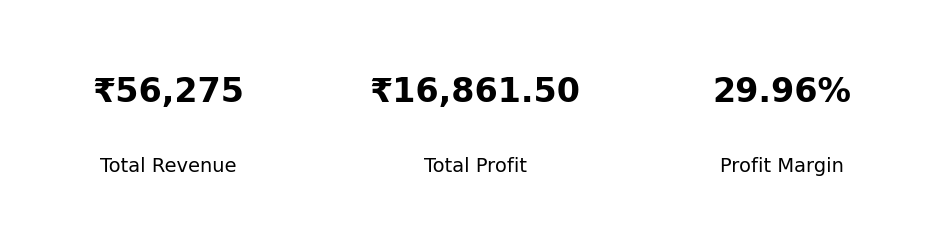

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 3))

ax.axis('off')

ax.text(0.17, 0.6, f'₹{total_revenue:,.0f}',
        ha='center', fontsize=24, fontweight='bold')
ax.text(0.17, 0.3, 'Total Revenue',
        ha='center', fontsize=14)

ax.text(0.50, 0.6, f'₹{total_profit:,.2f}',
        ha='center', fontsize=24, fontweight='bold')
ax.text(0.50, 0.3, 'Total Profit',
        ha='center', fontsize=14)

ax.text(0.83, 0.6, f'{profit_margin:.2f}%',
        ha='center', fontsize=24, fontweight='bold')
ax.text(0.83, 0.3, 'Profit Margin',
        ha='center', fontsize=14)

plt.show()

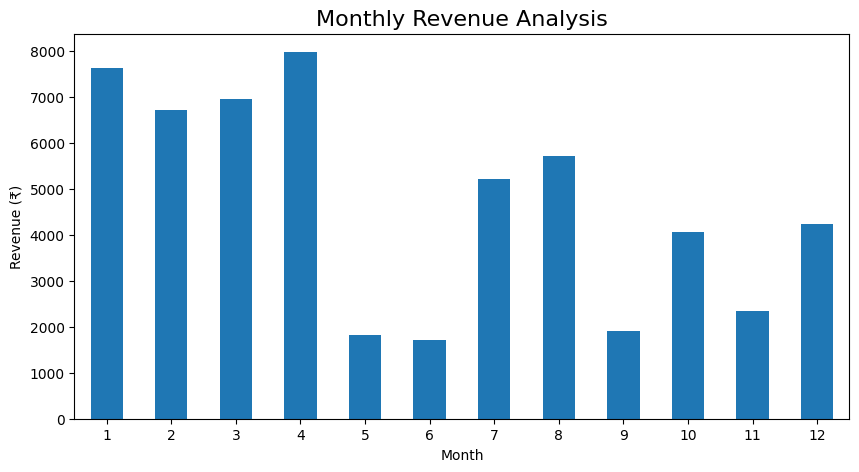

In [ ]:
monthly_revenue = df.groupby('month')['Revenue'].sum().sort_index()

plt.figure(figsize=(10, 5))

monthly_revenue.plot(kind='bar')

plt.title('Monthly Revenue Analysis', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=0)

plt.show()

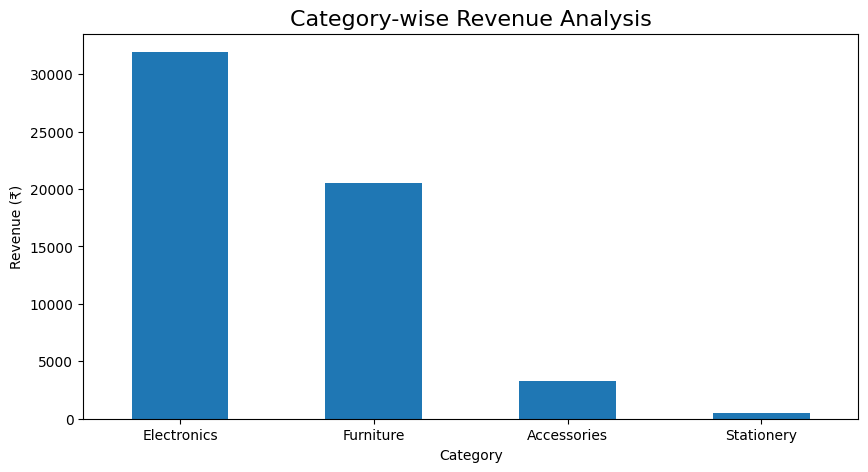

In [ ]:
category_revenue = df.groupby('category')['Revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

category_revenue.plot(kind='bar')

plt.title('Category-wise Revenue Analysis', fontsize=16)
plt.xlabel('Category')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=0)

plt.show()

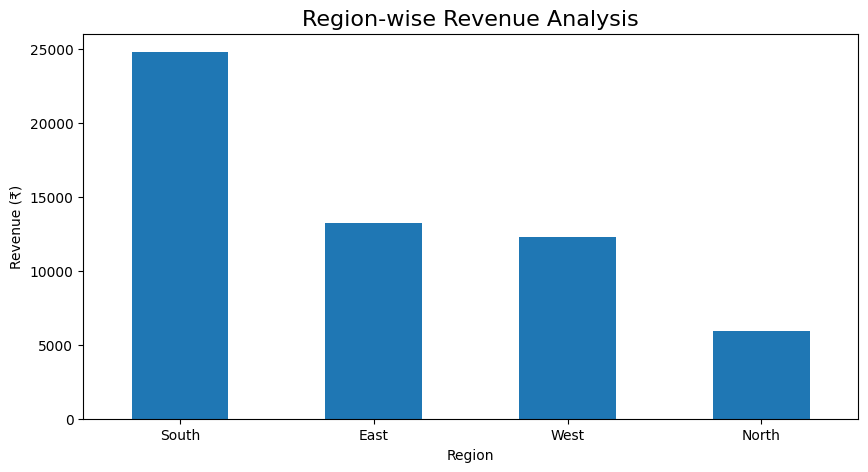

In [ ]:
region_revenue = df.groupby('region')['Revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

region_revenue.plot(kind='bar')

plt.title('Region-wise Revenue Analysis', fontsize=16)
plt.xlabel('Region')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=0)

plt.show()

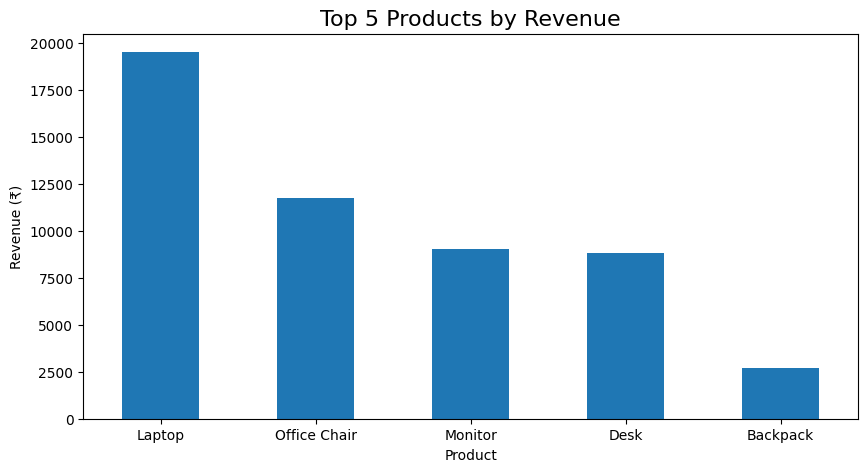

In [ ]:
top_products = df.groupby('product')['Revenue'].sum().sort_values(ascending=False).head(5)

plt.figure(figsize=(10, 5))

top_products.plot(kind='bar')

plt.title('Top 5 Products by Revenue', fontsize=16)
plt.xlabel('Product')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=0)

plt.show()

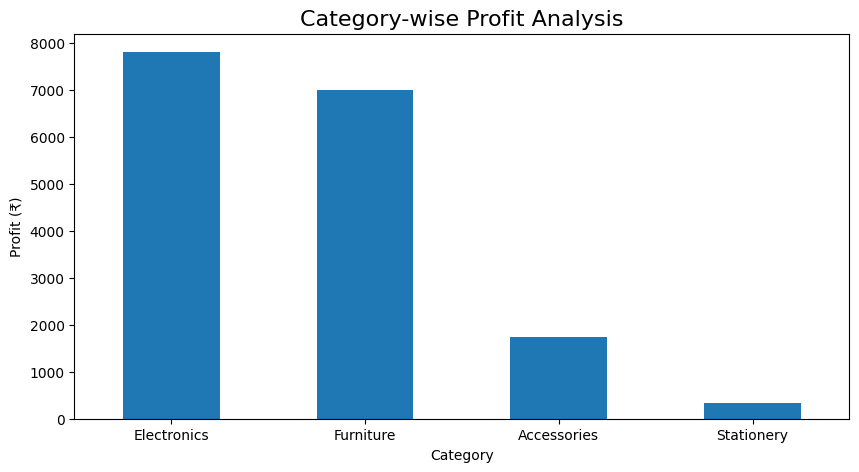

In [ ]:
category_profit = df.groupby('category')['Profit'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

category_profit.plot(kind='bar')

plt.title('Category-wise Profit Analysis', fontsize=16)
plt.xlabel('Category')
plt.ylabel('Profit (₹)')
plt.xticks(rotation=0)

plt.show()


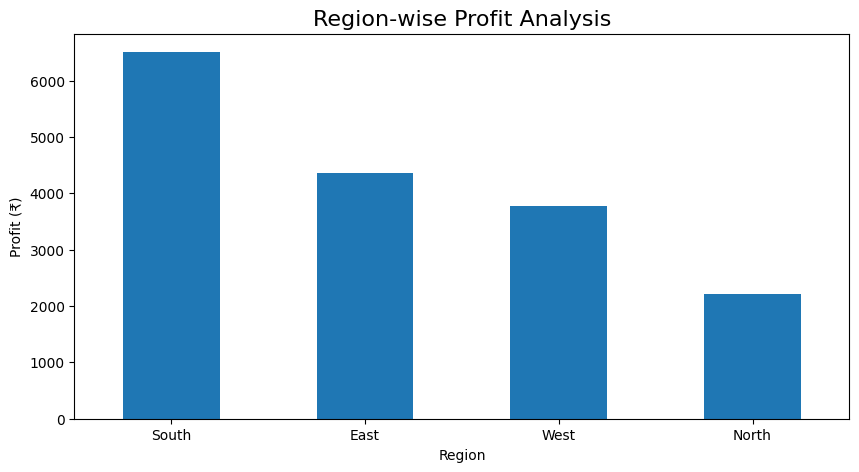

In [ ]:
region_profit = df.groupby('region')['Profit'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

region_profit.plot(kind='bar')

plt.title('Region-wise Profit Analysis', fontsize=16)
plt.xlabel('Region')
plt.ylabel('Profit (₹)')
plt.xticks(rotation=0)

plt.show()

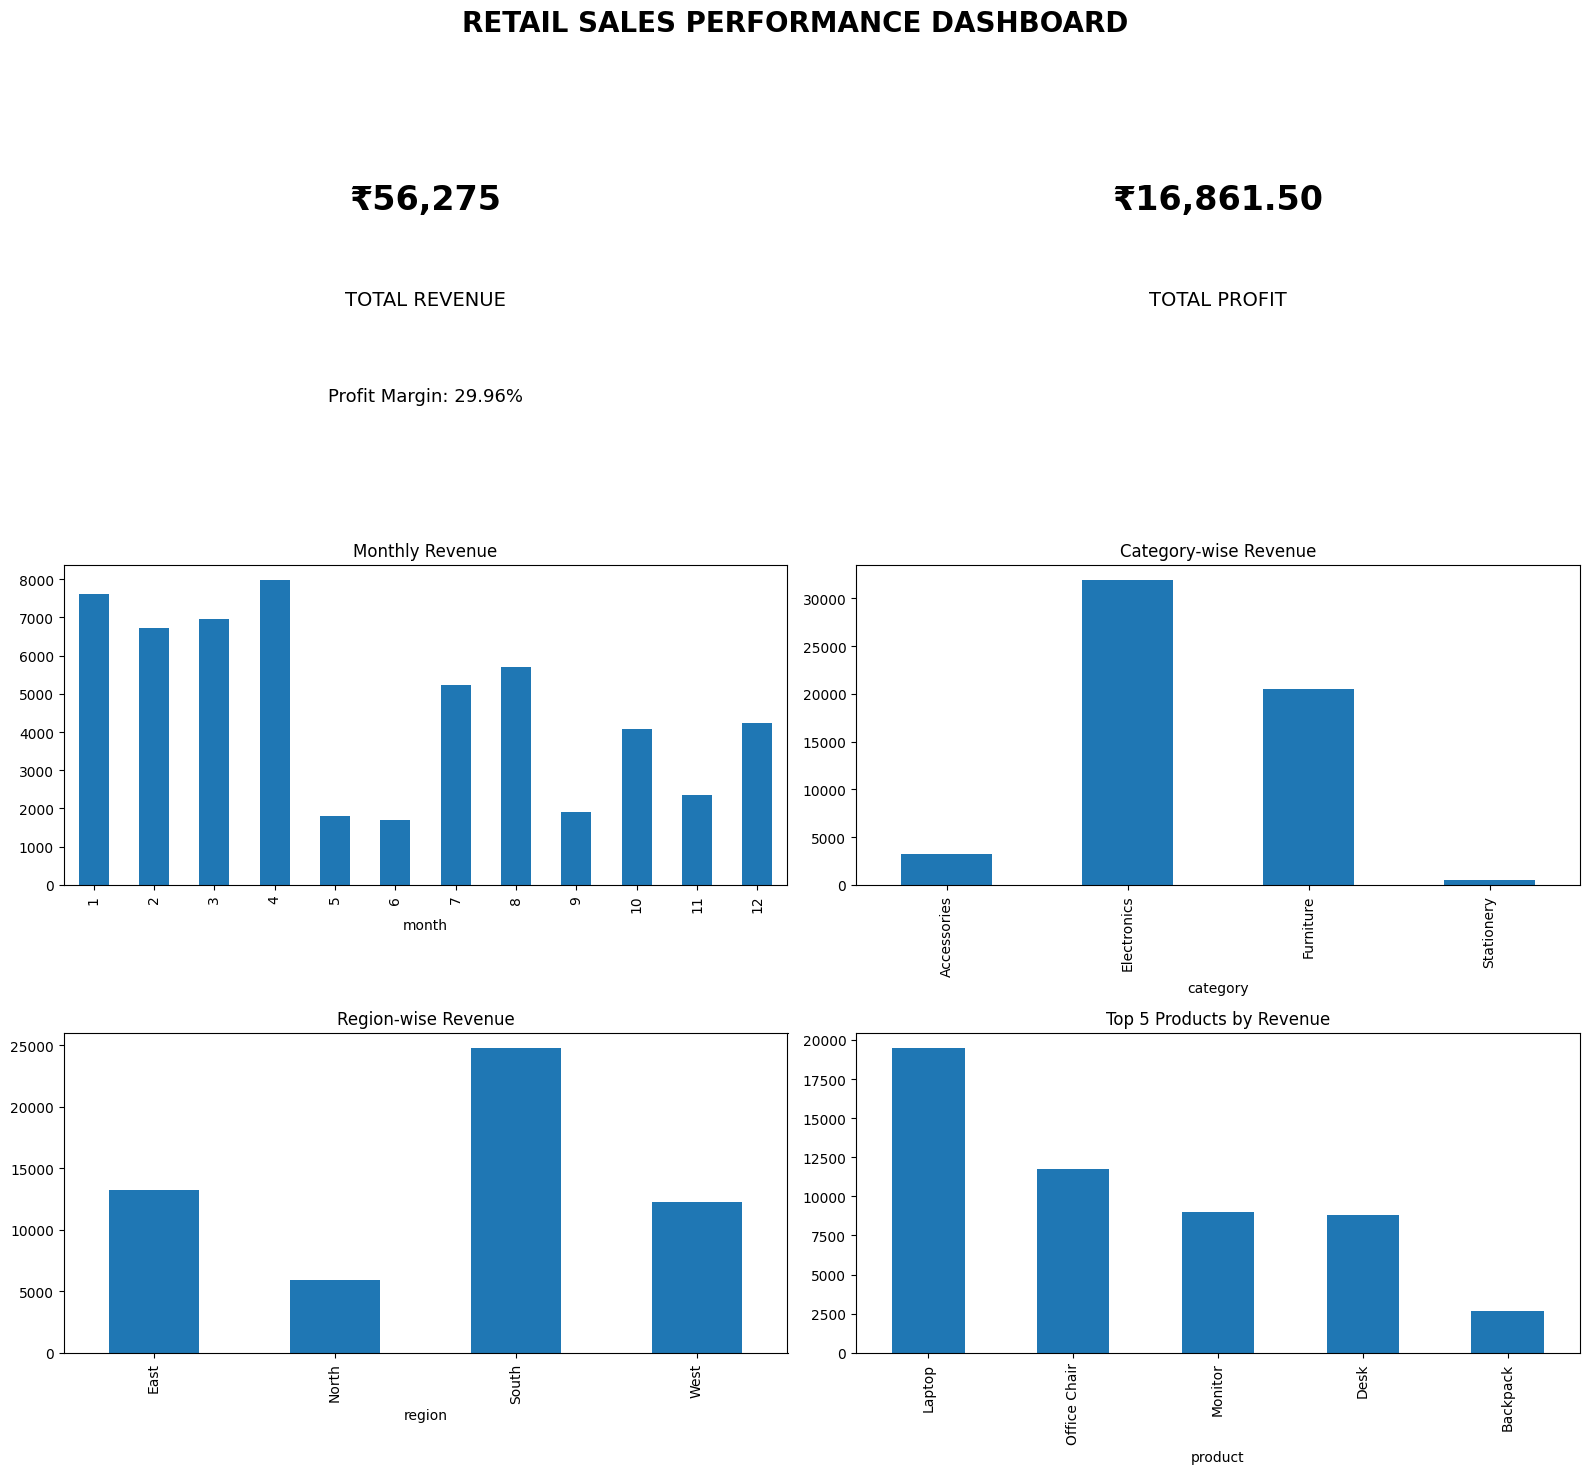

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(16, 15))

fig.suptitle('RETAIL SALES PERFORMANCE DASHBOARD',
             fontsize=20, fontweight='bold')

# KPI calculations
total_revenue = df['Revenue'].sum()
total_profit = df['Profit'].sum()
profit_margin = (total_profit / total_revenue) * 100

# KPI cards
# KPI cards
axes[0, 0].axis('off')
axes[0, 0].text(0.5, 0.65, f'₹{total_revenue:,.0f}',
                ha='center', fontsize=24, fontweight='bold')
axes[0, 0].text(0.5, 0.35, 'TOTAL REVENUE',
                ha='center', fontsize=14)

axes[0, 1].axis('off')
axes[0, 1].text(0.5, 0.65, f'₹{total_profit:,.2f}',
                ha='center', fontsize=24, fontweight='bold')
axes[0, 1].text(0.5, 0.35, 'TOTAL PROFIT',
                ha='center', fontsize=14)

axes[0, 0].text(0.5, 0.05, f'Profit Margin: {profit_margin:.2f}%',
                ha='center', fontsize=13)

# Monthly revenue
df.groupby('month')['Revenue'].sum().sort_index().plot(
    kind='bar', ax=axes[1, 0], title='Monthly Revenue'
)

# Category revenue
df.groupby('category')['Revenue'].sum().plot(
    kind='bar', ax=axes[1, 1], title='Category-wise Revenue'
)

# Region revenue
df.groupby('region')['Revenue'].sum().plot(
    kind='bar', ax=axes[2, 0], title='Region-wise Revenue'
)

# Top 5 products
df.groupby('product')['Revenue'].sum().nlargest(5).plot(
    kind='bar', ax=axes[2, 1], title='Top 5 Products by Revenue'
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('retail_sales_dashboard.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
from google.colab import files

files.download('retail_sales_dashboard.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>